# Sweeper Finder: shape features, the fit, first outcome comparison

This notebook runs on the 2,500-pitch sample that ships with the package, so it works offline. The numbers in the README come from the full 2023-24 run (`sweeper-finder run`); this is the same code on a small sample, to look at the features before trusting a model.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sweeper_finder import shapes, outcomes, integrity
from sweeper_finder.data.sample import load_sample
from sweeper_finder.mixture import SweeperMixture

raw = load_sample()
flagged = outcomes.add_outcomes(raw)
pool, counts = shapes.slider_pool(flagged)
counts

{'all_pitches': 2500,
 'slider_class': 2500,
 'missing_shape_data': 0,
 'implausible_speed': 0,
 'implausible_movement': 0,
 'modelled': 2500}

## 1. The sign of horizontal break depends on the pitcher's hand

Raw `pfx_x` has opposite signs for right- and left-handers' glove-side break. If that is not fixed first, a mixture would build separate sweeper components for each hand. After mirroring, every pitch type should be positive for both hands.

In [2]:
raw_mean = (12 * raw.groupby(['pitch_type', 'p_throws'])['pfx_x'].mean()).unstack().round(2)
print('raw pfx_x, inches'); print(raw_mean)
print('mirrored glove-side break, inches'); print(integrity.mirror_check(pool))

raw pfx_x, inches
p_throws        L      R
pitch_type              
SL          -4.27   4.57
ST         -13.74  13.87
SV         -11.28  15.66
mirrored glove-side break, inches
p_throws        L      R
pitch_type              
SL           4.27   4.57
ST          13.74  13.87
SV          11.28  15.66


## 2. Distributions of the three features, and outliers

Before fitting anything: are the ranges plausible and do the extremes make sense?

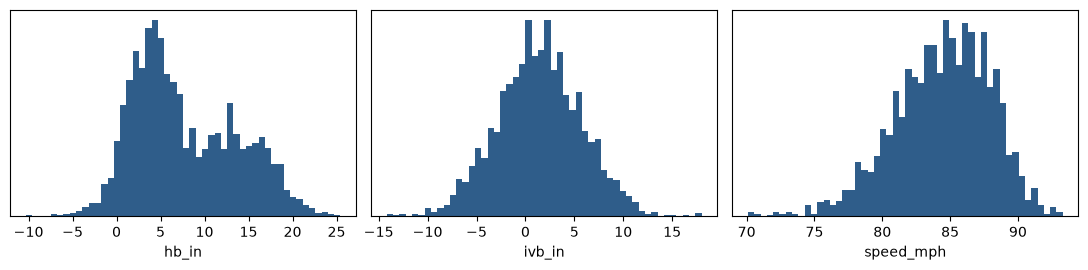

            count  mean  std   min   25%   50%   75%   max
hb_in      2500.0   7.8  5.9 -10.3   3.2   6.4  12.6  25.4
ivb_in     2500.0   1.4  4.3 -14.2  -1.4   1.4   4.3  18.0
speed_mph  2500.0  84.4  3.5  70.1  82.1  84.7  87.1  93.3
largest glove-side break
   player_name pitch_type  hb_in  ivb_in  speed_mph
   Adam, Jason         ST   25.4    -3.5       77.5
Roberts, Ethan         ST   24.5     3.1       81.1
 Bummer, Aaron         ST   24.2     0.5       82.2
   Webb, Logan         ST   24.0    -2.6       81.9
slowest
    player_name pitch_type  hb_in  ivb_in  speed_mph
Yarbrough, Ryan         ST   12.8    11.5       70.1
Yarbrough, Ryan         ST   18.1     3.0       70.3
     Hill, Rich         ST   22.6     3.7       70.3


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(11, 2.8))
for ax, col in zip(axes, shapes.FEATURES):
    ax.hist(pool[col], bins=50, color='#2f5d8a'); ax.set_xlabel(col); ax.set_yticks([])
fig.tight_layout(); plt.show()
print(pool[shapes.FEATURES].describe().round(1).T)
extremes = pool.nlargest(4, 'hb_in')[['player_name', 'pitch_type', 'hb_in', 'ivb_in', 'speed_mph']]
slowest = pool.nsmallest(3, 'speed_mph')[['player_name', 'pitch_type', 'hb_in', 'ivb_in', 'speed_mph']]
print('largest glove-side break'); print(extremes.round(1).to_string(index=False))
print('slowest'); print(slowest.round(1).to_string(index=False))

## 3. Fit the mixture and look at the components

Four components, as the BIC rule picks on the full data. The sweeper-like components are the ones the weighted 2-means on break puts in the high-break group.

In [4]:
X = pool[shapes.FEATURES].to_numpy()
mix = SweeperMixture.fit(X, k=4)
pool['sweeper_prob'] = mix.sweeper_prob(X)
pool['sweeper_like'] = pool['sweeper_prob'] >= 0.5
print(mix.components().to_string(index=False))
print('sweeper-like share:', round(pool['sweeper_like'].mean(), 3))
print('Statcast ST share:', round((pool['pitch_type'] == 'ST').mean(), 3))
print(pd.crosstab(pool['pitch_type'], pool['sweeper_like']))

 component  hb_in  ivb_in  speed_mph  weight  sweeper_like
         0  14.58   -1.06      81.93   0.242          True
         2  12.20    3.96      81.84   0.162          True
         3   4.17   -0.60      85.21   0.304         False
         1   3.40    4.19      87.11   0.292         False
sweeper-like share: 0.386
Statcast ST share: 0.324
sweeper_like  False  True 
pitch_type                
SL             1451    176
ST               79    732
SV                4     58


## 4. Does the label relate to outcomes?

A derived feature should be checked against the outcome it is supposed to matter for, without binning it. Here, whiffs per swing and chases as a smooth running average over pitches sorted by glove-side break (300-pitch window). It is a sample of 2,500 pitches from many pitchers, so this is only a shape check, not an estimate.

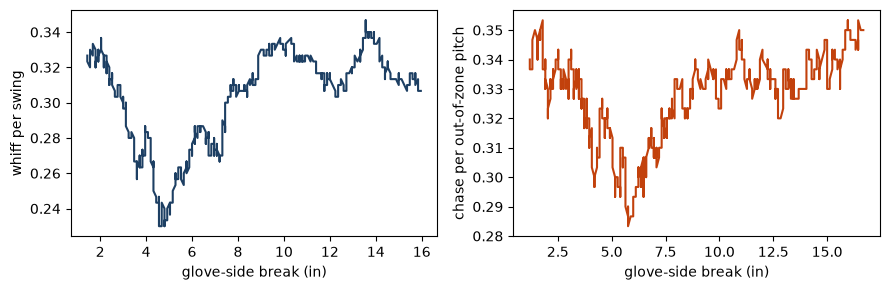

 sweeper_like    n   csw  whiff  chase  xwobacon
        False 1534 0.278  0.285  0.322      0.34
         True  966 0.304  0.313  0.343      0.29


In [5]:
s = pool.sort_values('hb_in')
sw = s[s['swing']]
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(sw['hb_in'], sw['whiff'].astype(float).rolling(300, center=True).mean(), color='#1d3f63')
ax[0].set_xlabel('glove-side break (in)'); ax[0].set_ylabel('whiff per swing')
oz = s[~s['in_zone']]
ax[1].plot(oz['hb_in'], oz['swing'].astype(float).rolling(300, center=True).mean(), color='#c2410c')
ax[1].set_xlabel('glove-side break (in)'); ax[1].set_ylabel('chase per out-of-zone pitch')
fig.tight_layout(); plt.show()
rows = []
for flag, g in pool.groupby('sweeper_like'):
    a = outcomes.rates(outcomes.aggregate(g.assign(_g=flag), ['_g'])).iloc[0]
    rows.append({'sweeper_like': flag, 'n': int(a['n']), 'csw': a['csw'], 'whiff': a['whiff'], 'chase': a['chase'], 'xwobacon': a['xwobacon']})
print(pd.DataFrame(rows).round(3).to_string(index=False))

## What this does not show

Differences between the two rows above mix pitch quality with pitcher quality: the sample is 570 pitchers, each with a handful of pitches. The README's comparison is within pitcher (a pitcher's sweeper-like pitches against his own other pitches) on 322,391 pitches, and it finds that against his other sliders the whiff difference disappears.